# AAPL Stock Price Prediction

Name: Leonardus Hasan

NIM: 2802553480

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [23]:
df = pd.read_csv("AAPL.csv")

## EDA

In [24]:
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


In [25]:
df.tail()

,Date,Open,High,Low,Close,Adj Close,Volume
9904,2020-03-26,246.520004,258.679993,246.360001,258.440002,258.440002,63021800
9905,2020-03-27,252.750000,255.869995,247.050003,247.740005,247.740005,51054200
9906,2020-03-30,250.740005,255.520004,249.399994,254.809998,254.809998,41994100
9907,2020-03-31,255.600006,262.489990,252.000000,254.289993,254.289993,49250500
9908,2020-04-01,246.500000,248.720001,239.130005,240.910004,240.910004,43956200


This dataset consists of AAPL stock data ranging from December 12, 1980, to April 1, 2020. For this problem, only the 'Date' and 'Close' columns are used, so the others can be removed.

In [26]:
df = df[['Date', 'Close']]

In [27]:
df.describe()

,Close
count,9909.000000
mean,32.618030
std,58.471899
min,0.196429
25%,1.071429
50%,1.732143
75%,35.761429
max,327.200012


This stock has the lowest closing price of 0.196, an average closing price of 32.618, and a highest price of 327.2.

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9909 entries, 0 to 9908
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    9909 non-null   object 
 1   Close   9909 non-null   float64
dtypes: float64(1), object(1)
memory usage: 155.0+ KB


The 'date' column is currently of the object type. Since it represents a date, it needs to be converted to the date type.

In [29]:
df['Date'] = pd.to_datetime(df['Date'])

In [30]:
df.head(5)

,Date,Close
0,1980-12-12,0.513393
1,1980-12-15,0.486607
2,1980-12-16,0.450893
3,1980-12-17,0.462054
4,1980-12-18,0.475446


The stock data above is already sorted by date. Therefore, we no longer need to sort the dates from beginning to end.

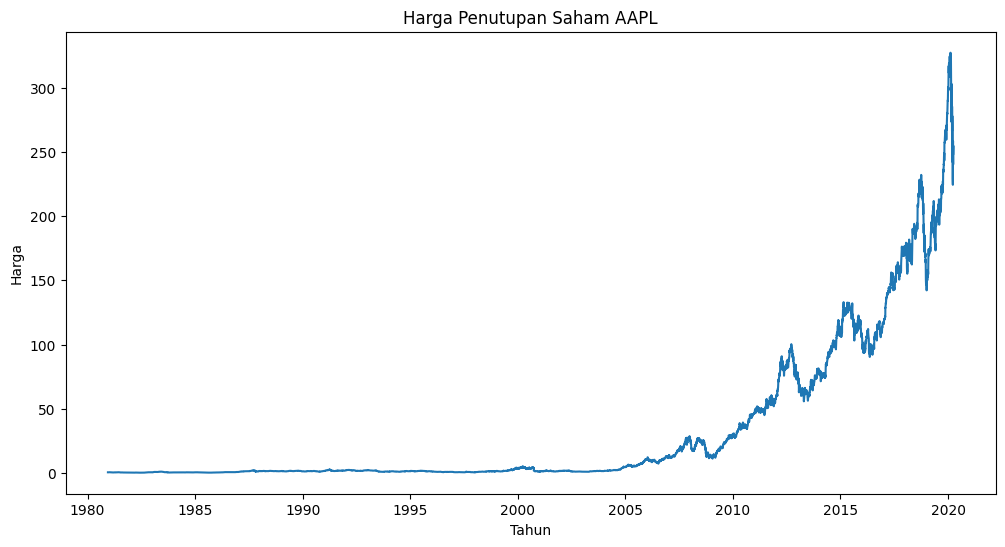

In [31]:
plt.figure(figsize=(12,6))
plt.plot(df['Date'], df['Close'])
plt.title("Harga Penutupan Saham AAPL")
plt.xlabel("Tahun")
plt.ylabel("Harga")
plt.show()

Based on the graph above, the following information can be observed:
- As the subject of analysis is a stock, the data constitutes a time series spanning from 1980 to 2020.
- There was no significant increase between 1980 and the end of 2004; a rise only became apparent from late 2004 through 2020, despite intermittent declines during that period.
- Stock price growth began gradually in 2005. Subsequently, the period from 2010 to 2020 showed a steeper and more rapid rise in stock prices compared to previous years.
- The rise in AAPL's stock price indicates a bullish trend that has persisted since 1980 (Bullish = an upward trend in stock prices).
- The stock data is non-stationary, as there are observable trends of rising and falling prices following 2005 and around the year 2000.

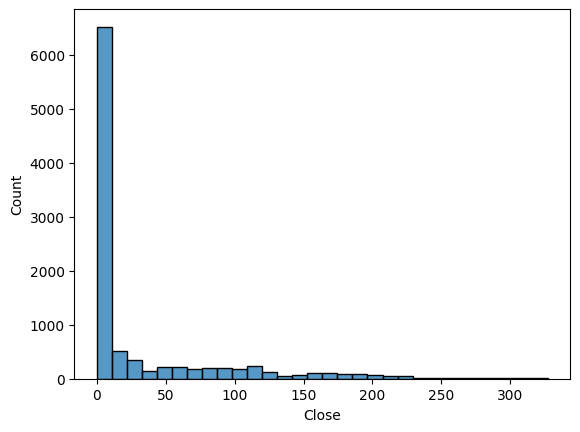

In [32]:
sns.histplot(df['Close'], bins=30)
plt.show()

The dataset appears left-skewed regarding closing prices (approximately 0–1). This is because, based on stock price movement patterns between 1980 and 2005, the closing prices fell within a relatively low range, causing the data to skew to the left.

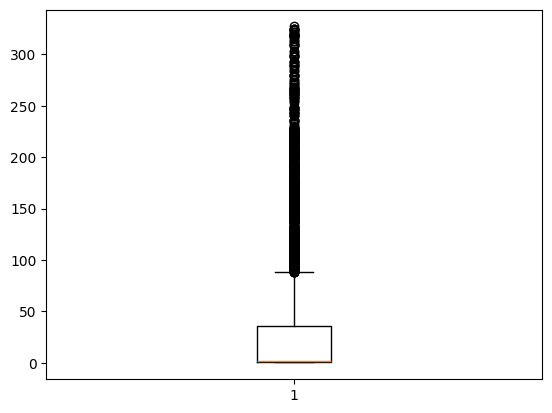

In [33]:
plt.boxplot(df['Close'])
plt.show()

Outliers were detected in this stock dataset. However, this is normal and expected, as the data consists of stock figures; high closing prices simply reflect market conditions at the time. Therefore, the outliers have been retained to enable the LSTM model to learn the patterns of stock price movements.

## Preprocessing

The stock data is current as of April 1, 2020. Therefore, the test data begins on April 1, 2019, while the training data spans the period from December 12, 1980, to March 29, 2019.

In [34]:
train = df[df['Date'] < '2019-04-01']
test = df[df['Date'] >= '2019-04-01']

In [35]:
test

,Date,Close
9655,2019-04-01,191.240005
9656,2019-04-02,194.020004
9657,2019-04-03,195.350006
9658,2019-04-04,195.690002
9659,2019-04-05,197.000000
...,...,...
9904,2020-03-26,258.440002
9905,2020-03-27,247.740005
9906,2020-03-30,254.809998
9907,2020-03-31,254.289993


In [36]:
train

,Date,Close
0,1980-12-12,0.513393
1,1980-12-15,0.486607
2,1980-12-16,0.450893
3,1980-12-17,0.462054
4,1980-12-18,0.475446
...,...,...
9650,2019-03-25,188.740005
9651,2019-03-26,186.789993
9652,2019-03-27,188.470001
9653,2019-03-28,188.720001


In [37]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train[['Close']])
test_scaled = scaler.transform(test[['Close']])

In [38]:
def input_output(data, window=5):
    X, y = [], []
    for i in range(len(data)-window):
        X.append(data[i:i+window])
        y.append(data[i+window])
    return np.array(X), np.array(y)

In [39]:
X_train_temp, y_train_temp = input_output(train_scaled)
X_train, X_val, y_train, y_val = train_test_split(X_train_temp, y_train_temp, test_size=0.1, shuffle=False)

In [40]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(y_val.shape)

(8685, 5, 1)
(8685, 1)
(965, 5, 1)
(965, 1)


After splitting the training data into training and validation sets, 8,685 samples were obtained for training and 965 samples for validation. Each sample has a shape of (5, 1), meaning it consists of five closing price data points from five trading days as input—comprising a single feature (the closing value)—while the target to be predicted is the closing price of the following day (horizon = 1).

In [41]:
combined = np.concatenate([train_scaled[-5:], test_scaled])
X_test, y_test = input_output(combined)

In [42]:
print(X_test.shape)
print(y_test.shape)

(254, 5, 1)
(254, 1)


In [43]:
baseline = Sequential([LSTM(units=50, activation='relu', input_shape=(5,1)), Dense(1)])
baseline.compile(optimizer='adam', loss='mse',metrics=['mae'])

In [44]:
history = baseline.fit(X_train, y_train, validation_data=(X_val,y_val), epochs=50, batch_size=32, verbose=1)

Epoch 1/50
272/272 [==============================] - 15s 46ms/step - loss: 0.0020 - mae: 0.0160 - val_loss: 3.0891e-04 - val_mae: 0.0129
Epoch 2/50
272/272 [==============================] - 10s 36ms/step - loss: 1.3090e-05 - mae: 0.0019 - val_loss: 3.4291e-04 - val_mae: 0.0126
Epoch 3/50
272/272 [==============================] - 10s 37ms/step - loss: 1.2508e-05 - mae: 0.0018 - val_loss: 3.3926e-04 - val_mae: 0.0126
Epoch 4/50
272/272 [==============================] - 11s 42ms/step - loss: 1.2759e-05 - mae: 0.0019 - val_loss: 3.4697e-04 - val_mae: 0.0127
Epoch 5/50
272/272 [==============================] - 11s 41ms/step - loss: 1.2626e-05 - mae: 0.0019 - val_loss: 3.2135e-04 - val_mae: 0.0125
Epoch 6/50
272/272 [==============================] - 11s 42ms/step - loss: 1.2984e-05 - mae: 0.0020 - val_loss: 4.9202e-04 - val_mae: 0.0150
Epoch 7/50
272/272 [==============================] - 11s 41ms/step - loss: 1.3065e-05 - mae: 0.0020 - val_loss: 4.8000e-04 - val_mae: 0.0148
Epoch 8/50

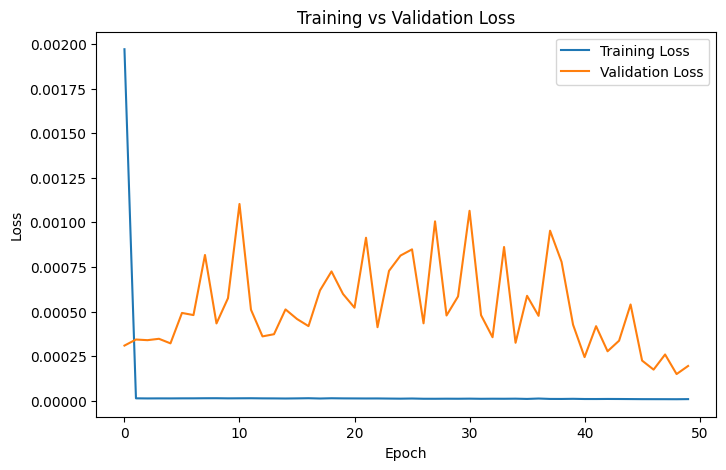

In [45]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Based on the LOSS graph above, the following conclusions can be drawn:
- Training loss dropped sharply during the first epoch before approaching zero.
- Validation loss fluctuated within the range of 0.00002 to 0.0007.
- The model was able to learn the training data very well; however, performance on the validation data did not improve and tended to fluctuate.
- There are indications of slight overfitting.

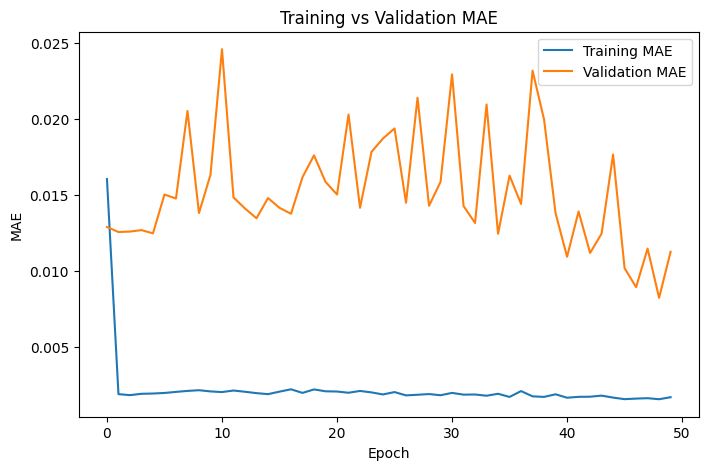

In [46]:
plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.title('Training vs Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.show()

The results shown in the Training vs. Validation MAE graph above are similar to those of the training vs. validation loss graph, indicating that the model learns the training data very well. Meanwhile, the validation MAE fluctuates between approximately 0.110 and 0.200. This suggests that the model's ability to generalize to the data is suboptimal. Furthermore, there are indications of overfitting, as the model performs well on the training data but shows degraded performance when tested against the validation data.

Therefore, the next phase of model development will involve architectural modifications or hyperparameter adjustments, such as:
- Adding Dropout to reduce overfitting
- Implementing EarlyStopping to halt training when validation loss ceases to improve
- Adjusting the number of LSTM units to provide the model with greater representational capacity for learning stock price movement patterns

In [80]:
modified = Sequential([LSTM(63, activation='relu', input_shape=(5,1)),Dropout(0.1),Dense(16, activation='relu'), Dense(1)])
modified.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [81]:
es = EarlyStopping(monitor='val_loss',patience=8, restore_best_weights=True)

In [82]:
history = modified.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=50, batch_size=32, callbacks=[es], shuffle=False)

Epoch 1/50
272/272 [==============================] - 16s 49ms/step - loss: 8.2312e-04 - mae: 0.0127 - val_loss: 0.0100 - val_mae: 0.0779
Epoch 2/50
272/272 [==============================] - 11s 40ms/step - loss: 0.0053 - mae: 0.0389 - val_loss: 7.0085e-04 - val_mae: 0.0215
Epoch 3/50
272/272 [==============================] - 11s 41ms/step - loss: 0.0031 - mae: 0.0322 - val_loss: 5.8282e-04 - val_mae: 0.0193
Epoch 4/50
272/272 [==============================] - 12s 43ms/step - loss: 0.0012 - mae: 0.0195 - val_loss: 0.0017 - val_mae: 0.0287
Epoch 5/50
272/272 [==============================] - 11s 41ms/step - loss: 5.4622e-04 - mae: 0.0146 - val_loss: 0.0010 - val_mae: 0.0261
Epoch 6/50
272/272 [==============================] - 12s 42ms/step - loss: 3.8464e-04 - mae: 0.0123 - val_loss: 0.0023 - val_mae: 0.0325
Epoch 7/50
272/272 [==============================] - 11s 40ms/step - loss: 2.0115e-04 - mae: 0.0089 - val_loss: 0.0015 - val_mae: 0.0300
Epoch 8/50
272/272 [==================

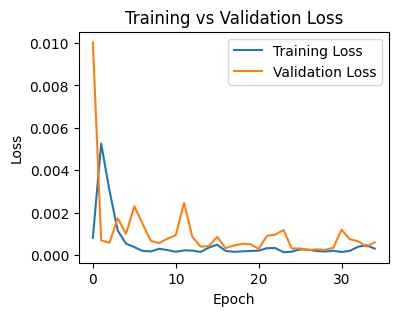

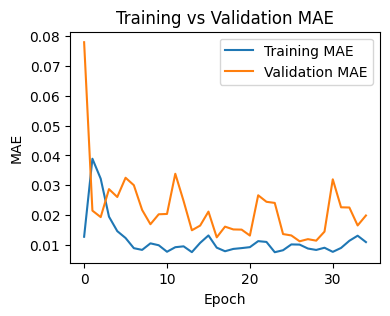

In [87]:
plt.figure(figsize=(4,3))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure(figsize=(4,3))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Training vs Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.show()

Based on the Training vs. Validation Loss and Training vs. Validation MAE graphs above, several points can be identified as follows:
- After architectural modifications, the validation loss value is increasingly able to learn price movement patterns. This is indicated by the graph approaching the training value.
- The model detects that potential outliers begin to appear at epoch 12.

In [92]:
y_pred_baseline = baseline.predict(X_test)
y_pred_modified = modified.predict(X_test)

y_true = scaler.inverse_transform(y_test)
y_pred_baseline = scaler.inverse_transform(y_pred_baseline)
y_pred_modified = scaler.inverse_transform(y_pred_modified)

8/8 [==============================] - 0s 11ms/step


In [89]:
rmse = np.sqrt(mean_squared_error(y_true, y_pred_baseline))
mae = mean_absolute_error(y_true, y_pred_baseline)
mape = mean_absolute_percentage_error(y_true, y_pred_baseline) * 100

print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.2f}%")

RMSE : 6.1176
MAE  : 4.1074
MAPE : 1.71%


In [93]:
rmse = np.sqrt(mean_squared_error(y_true, y_pred_modified))
mae = mean_absolute_error(y_true, y_pred_modified)
mape = mean_absolute_percentage_error(y_true, y_pred_modified) * 100

print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.2f}%")

RMSE : 12.9486
MAE  : 8.4706
MAPE : 3.26%


The graphs reveal that the training loss and validation loss lines are converging, indicating that the modified model possesses better generalization capabilities. A similar trend is observed in the Training MAE and Validation MAE graphs, where the gap between the two curves is narrower than that of the baseline model. This suggests improved generalization during training, evidenced by the lines drawing closer together compared to the baseline. However, the baseline model generally outperforms the modified model in terms of RMSE, MAE, and MAPE metrics: a lower RMSE (6.1176 < 12.9486) indicates predictions closer to actual values; a lower MAE (4.1074 < 8.4706) signifies greater prediction accuracy; and a lower MAPE (1.71% < 3.26%) reflects a lower percentage error. The higher values ​​for these three parameters in the modified model may stem from the introduction of unsuitable model complexity, which hindered the model's ability to optimally learn price movement patterns.

Consequently, the baseline model demonstrates superior prediction accuracy compared to the modified model.

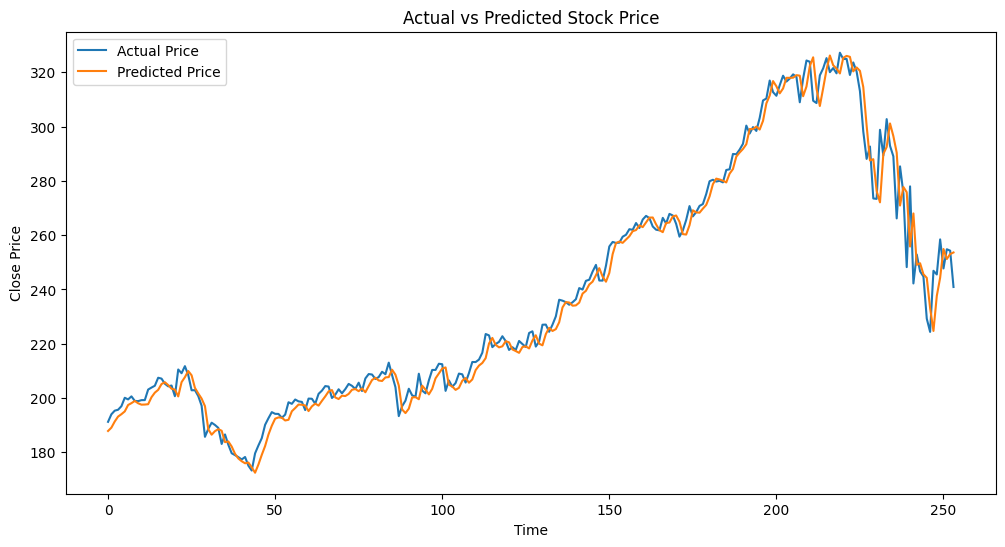

In [94]:
plt.figure(figsize=(12,6))

plt.plot(y_true, label='Actual Price')
plt.plot(y_pred_baseline, label='Predicted Price')

plt.title('Actual vs Predicted Stock Price')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()

plt.show()

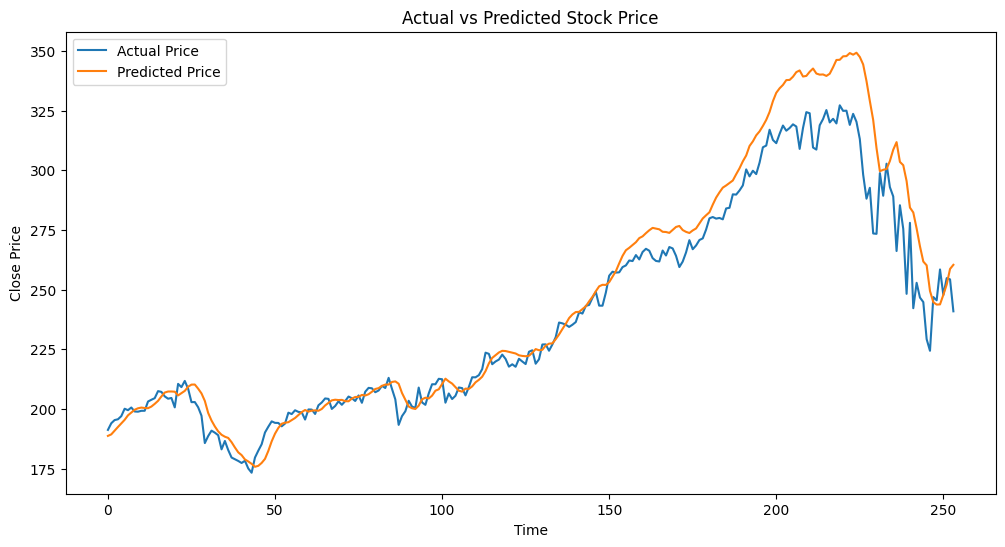

In [95]:
plt.figure(figsize=(12,6))

plt.plot(y_true, label='Actual Price')
plt.plot(y_pred_modified, label='Predicted Price')

plt.title('Actual vs Predicted Stock Price')
plt.xlabel('Time')
plt.ylabel('Close Price')
plt.legend()

plt.show()